In [1]:
import numpy as np
import scipy.linalg as la
from data import init_geodesic
from solver import GeodesicEstimator
from utils import projection_mse, compute_PSNR, compute_SSIM, compute_RMSE, normalize_np
from data_obs import generate_mc
from gnmr import GNMR_completion
from skimage.metrics import peak_signal_noise_ratio as psnr

## Processing Data

In [2]:
with np.load('img_utils/orig_mouse_data.npz') as data:
    data = data['arr_0']

In [3]:
x, y = data.shape[0], data.shape[1]
frames = data.shape[2]

In [4]:
vec_data = np.reshape(data, (-1, frames), order='F')
vec_data = vec_data / 255
vec_data_norm = vec_data - np.mean(vec_data, axis=0)

In [5]:
Xs = []

ell = 5 # Number of data samples per time index

st = 0
en = ell

for i in range(frames // ell):
    Xs.append(vec_data_norm[:, st:en])
    
    st += ell
    en += ell
    
T = len(Xs)

## Initialization

In [6]:
def obj_func(Ys, Xs, forward, mask):
    """
    Function for computing objective function value.
    """

    if isinstance(Ys, list):
        Ys = np.concatenate(Ys, axis=1)

    if isinstance(Xs, list):
        Xs = np.concatenate(Xs, axis=1)

    if isinstance(mask, list):
        mask = np.concatenate(mask, axis=1)

    return np.linalg.norm( Ys- forward(Xs, mask) )**2 / Xs.shape[1]

## Driver Code

In [7]:
FRAC_OBSERVED = 0.6
SIGMA = 0.01

NTRIALS = 1
NITERS = 2
RANK = 5

N_INNER_ITERS = 200

# GNMR algorithm options
options = {
    # general
    'verbose' : True,
    'alpha' : -1,  # (1: setting variant, 0: averaging variant, -1: updating variant)
    # number of iterations
    'max_outer_iter' : NITERS, 
    'max_inner_iter': N_INNER_ITERS,
    # early stopping criteria (-1 to disable a criterion)
    'stop_relRes':  5e-14,
    'stop_relDiff': 5e-14,
}

In [8]:
psnr_k_gnmr = np.zeros((NTRIALS, ))
psnr_twok_gnmr = np.zeros((NTRIALS, ))

ssim_k_gnmr = np.zeros((NTRIALS, ))
ssim_twok_gnmr = np.zeros((NTRIALS,))

rmse_k_gnmr = np.zeros((NTRIALS, ))
rmse_twok_gnmr = np.zeros((NTRIALS,))

for trial in range( NTRIALS ):
    print('Trial:', trial)
    
    # Generating data
    forward, transpose, masks = generate_mc(d=Xs[0].shape[0], ell=ell, T=T,frac_observed=FRAC_OBSERVED)

    # Generate masked data
    Ys = []

    for i, Xi in enumerate(Xs):
        Ys.append( forward(Xi, masks[i]) + np.random.randn(*Xi.shape)*SIGMA )

    # k-GNMR
    Y_concat = np.concatenate(Ys, axis=1)
    X_concat = np.concatenate(Xs, axis=1)
            
    X_k_gnmr, iter, _, _ = GNMR_completion(Y_concat, np.concatenate(masks, axis=1), RANK, **options)
    
    rmse_k_gnmr[trial] = compute_RMSE(X_k_gnmr, X_concat)
    psnr_k_gnmr[trial] = compute_PSNR(X_k_gnmr, X_concat)
    ssim_k_gnmr[trial] = compute_SSIM(X_k_gnmr, X_concat)
        
    print('PSNR:', psnr_k_gnmr[trial], 'RMSE Error:', rmse_k_gnmr[trial])  
    
    # 2k-GNMR
    X_twok_gnmr, iter, _, _ = GNMR_completion(Y_concat, np.concatenate(masks, axis=1), 2*RANK, **options)
    
    rmse_twok_gnmr[trial] = compute_RMSE(X_twok_gnmr, X_concat)
    psnr_twok_gnmr[trial] = compute_PSNR(X_twok_gnmr, X_concat)
    ssim_twok_gnmr[trial] = compute_SSIM(X_twok_gnmr, X_concat)
        
    print('PSNR:', psnr_twok_gnmr[trial], 'RMSE Error:', rmse_twok_gnmr[trial])  


Trial: 0
[INSIDE GNMR] iter: 1, relRes: 0.1981619734549039
[INSIDE GNMR] iter: 2, relRes: 0.0033657928585595284
PSNR: 21.325905607588673 RMSE Error: 0.09643991040705088
[INSIDE GNMR] iter: 1, relRes: 0.16453454832486988
[INSIDE GNMR] iter: 2, relRes: 0.0025423856806836096
PSNR: 21.006702821507854 RMSE Error: 0.10198810013290072


## Post-Processing Metrics

In [9]:
psnr_k_mean = np.mean(psnr_k_gnmr )
psnr_k_std = np.std(psnr_k_gnmr )

psnr_twok_mean = np.mean(psnr_twok_gnmr )
psnr_twok_std = np.std(psnr_twok_gnmr )

print('(k) PSNR:', psnr_k_mean, psnr_k_std)
print('(2k) PSNR:', psnr_twok_mean, psnr_twok_std)

ssim_k_mean = np.mean(ssim_k_gnmr )
ssim_k_std = np.std(ssim_k_gnmr )

ssim_twok_mean = np.mean(ssim_twok_gnmr )
ssim_twok_std = np.std(ssim_twok_gnmr )

print('(k) SSIM:', ssim_k_mean, ssim_k_std)
print('(2k) SSIM:', ssim_twok_mean, ssim_twok_std)

rmse_k_mean = np.mean(rmse_k_gnmr )
rmse_k_std = np.std(rmse_k_gnmr )

rmse_twok_mean = np.mean(rmse_twok_gnmr )
rmse_twok_std = np.std(rmse_twok_gnmr )

print('(k) RMSE:', rmse_k_mean, rmse_k_std)
print('(2k) RMSE:', rmse_twok_mean, rmse_twok_std)

(k) PSNR: 21.325905607588673 0.0
(2k) PSNR: 21.006702821507854 0.0
(k) SSIM: 0.673571177334617 0.0
(2k) SSIM: 0.6730591600997214 0.0
(k) RMSE: 0.09643991040705088 0.0
(2k) RMSE: 0.10198810013290072 0.0


In [10]:
import matplotlib.pyplot as plt

In [13]:
idx = 40

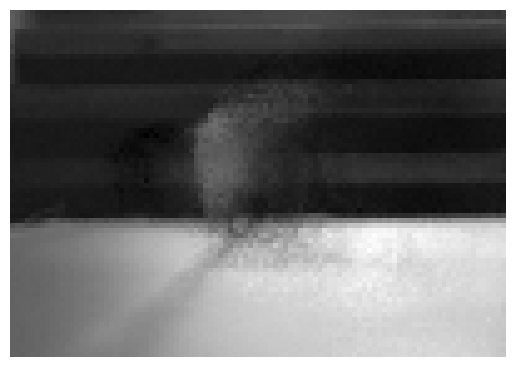

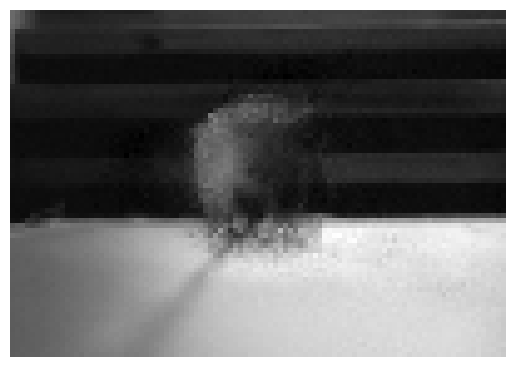

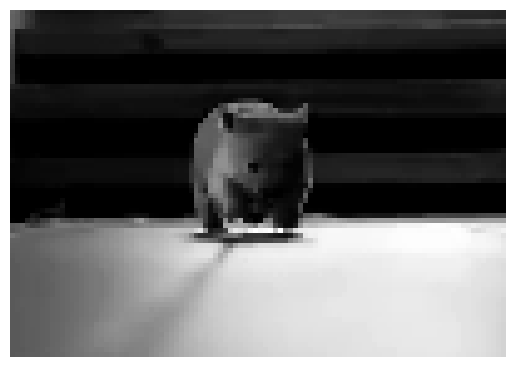

In [15]:

plt.imshow((np.reshape(X_k_gnmr[:, idx], (x,y), order='F')), cmap='gray')
plt.axis('off')
#plt.savefig(f'plane_images/curtain_k_gnmr_frame{idx}_noisy.png', bbox_inches='tight', pad_inches=0)
plt.show()

plt.imshow((np.reshape(X_twok_gnmr[:, idx], (x,y), order='F')), cmap='gray')
plt.axis('off')
plt.savefig(f'mouse_twok_gnmr_frame{idx}_r5.png', bbox_inches='tight', pad_inches=0)
plt.show()


plt.imshow((np.reshape(X_concat[:, idx], (x,y), order='F')), cmap='gray')
plt.axis('off')
#plt.savefig(f'images/curtainframe{idx}.png', bbox_inches='tight', pad_inches=0)
plt.show()

In [16]:
idx = 40

In [17]:
psnr(normalize_np(X_k_gnmr[:, idx]), normalize_np(X_concat[:, idx]))

21.158672100201066

In [18]:
psnr(normalize_np(X_twok_gnmr[:, idx]), normalize_np(X_concat[:, idx]))

23.396109298201285

In [ ]:
for i in range(X_twok_gnmr.shape[1]):
    print(i,  psnr(normalize_np(X_twok_gnmr[:, i]), normalize_np(X_concat[:, i])) )